# Лабораторная работа 2. Классификация. Нейронные сети

**Цель работы:** изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

## Задачи

1. Выбрать и подготовить датасет для классификации (`wine.csv`).
2. Реализовать и обучить восемь классификаторов пяти семейств:
   - наивный Байес — 4 варианта: `GaussianNB`, `MultinomialNB`, `ComplementNB`, `BernoulliNB`;
   - решающее дерево (`DecisionTreeClassifier`);
   - линейный дискриминантный анализ (`LinearDiscriminantAnalysis`);
   - метод опорных векторов (`SVC`, RBF-ядро);
   - метод k ближайших соседей (`KNeighborsClassifier`).
3. Оценить качество по пяти метрикам: Accuracy, Precision, Recall, F1-Score (macro), AUC-ROC (OvR).
4. Провести подбор гиперпараметров каждого метода и исследовать влияние параметров на качество.
5. Сравнить качество классификации на исходных признаках и на главных компонентах (PCA).
6. Построить нейронную сеть на TensorFlow, залогировать обучение в TensorBoard, провести эксперименты с архитектурой и гиперпараметрами.
7. Сравнить все подходы и сделать аргументированный вывод.

**Датасет:** `wine.csv` — химический анализ 178 образцов вина трёх сортов. Признаки — 13 числовых измерений (алкоголь, яблочная кислота, зола, фенолы, флаваноиды, пролин и др.), целевая переменная `Wine` ∈ {1, 2, 3}.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / 'src'))

import matplotlib
import numpy as np
import pandas as pd

matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display

import calc as cc
import classification_models as cm
import csv_to_dataframe as ctd
import dataset_description as dd
import hyperparameter_tuning as ht
import model_comparison as mc
import pca_analysis as pa
import plots as pl

RANDOM_STATE = 42
TARGET = 'Wine'
PCA_VARIANCE_THRESHOLD = 0.95
PCA_MAX_COMPONENTS = 10

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)


Модули проекта находятся в `src/`, поэтому добавление этой папки в `sys.path` позволяет импортировать их «как в `main.py`». Все визуализации будем генерировать через модуль `plots` в виде PNG-файлов и выводить через `IPython.display.Image` — так отчёт остаётся читаемым как в live-ноутбуке, так и в статическом HTML-экспорте.

Фиксируем `RANDOM_STATE = 42` и порог дисперсии PCA = 0.95, чтобы результаты совпадали с `main.py`.


In [2]:
data = ctd.csv_to_dataframe('wine.csv')
data = data.dropna(how='all').reset_index(drop=True)
data = data.dropna().reset_index(drop=True)

print(f'Размер датасета: {data.shape[0]} строк x {data.shape[1]} столбцов')
print('Число наблюдений по классам:')
print(data[TARGET].value_counts().sort_index().to_string())
print(f'Пропуски: {int(data.isnull().sum().sum())}')
data.head()


Размер датасета: 178 строк x 14 столбцов
Число наблюдений по классам:
Wine
1    59
2    71
3    48
Пропуски: 0


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


Датасет `wine` — 178 образцов, 13 числовых признаков, три класса примерно равной мощности (59 / 71 / 48), пропусков нет. Баланс классов достаточен, чтобы использовать accuracy как одну из основных метрик, но всё же будем также смотреть на macro-F1 — он чувствителен к качеству на каждом классе независимо от размера.

Признаки имеют разный масштаб: `Proline` доходит до 1680, `Hue` — до 1.71. Значит, для SVM, LDA, KNN и гауссова Байеса потребуется стандартизация; для Multinomial/Complement NB — неотрицательные признаки (MinMax), а для Bernoulli — дискретизация.


In [3]:
description = dd.DatasetDescription(data)
print(f'Sturges rule bins: {cc.calc_sturges_rule(len(data))}')
print(description)


Sturges rule bins: 8
DATASET DESCRIPTION
Shape: 178 rows x 14 columns

Columns and dtypes:
  - Wine: int64
  - Alcohol: float64
  - Malic.acid: float64
  - Ash: float64
  - Acl: float64
  - Mg: int64
  - Phenols: float64
  - Flavanoids: float64
  - Nonflavanoid.phenols: float64
  - Proanth: float64
  - Color.int: float64
  - Hue: float64
  - OD: float64
  - Proline: int64

Missing values per column:
  - Wine: 0
  - Alcohol: 0
  - Malic.acid: 0
  - Ash: 0
  - Acl: 0
  - Mg: 0
  - Phenols: 0
  - Flavanoids: 0
  - Nonflavanoid.phenols: 0
  - Proanth: 0
  - Color.int: 0
  - Hue: 0
  - OD: 0
  - Proline: 0

Numeric features summary:
                      count        mean         std     min       25%      50%       75%      max
Wine                  178.0    1.938202    0.775035    1.00    1.0000    2.000    3.0000     3.00
Alcohol               178.0   13.000618    0.811827   11.03   12.3625   13.050   13.6775    14.83
Malic.acid            178.0    2.336348    1.117146    0.74    1.6025 

`DatasetDescription` агрегирует: типы столбцов, пропуски, сводную статистику, кросстабы категориальных переменных и матрицу корреляций. В нашем случае категориальных признаков нет — все 13 признаков числовые, а `Wine` — целочисленный код класса.

Правило Стёрджеса даёт 8 бинов для 178 наблюдений — используем эту оценку для гистограмм.


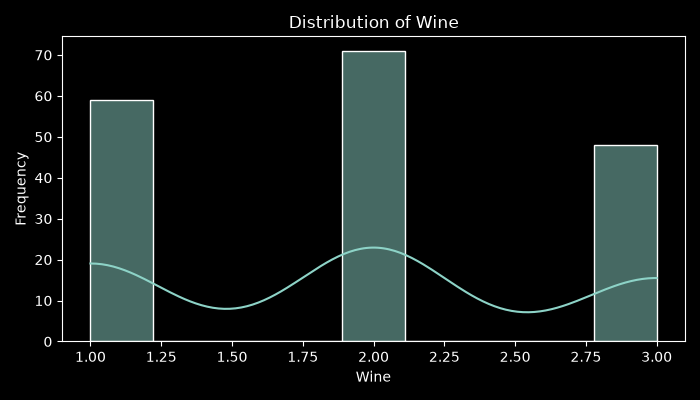

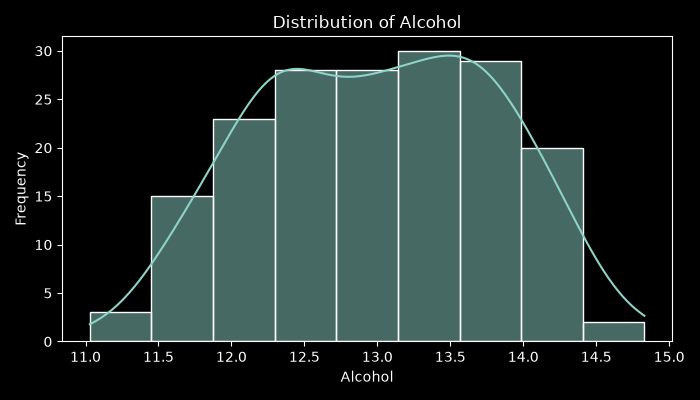

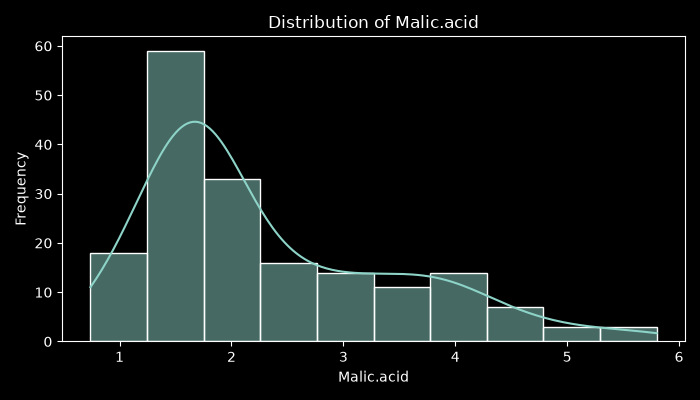

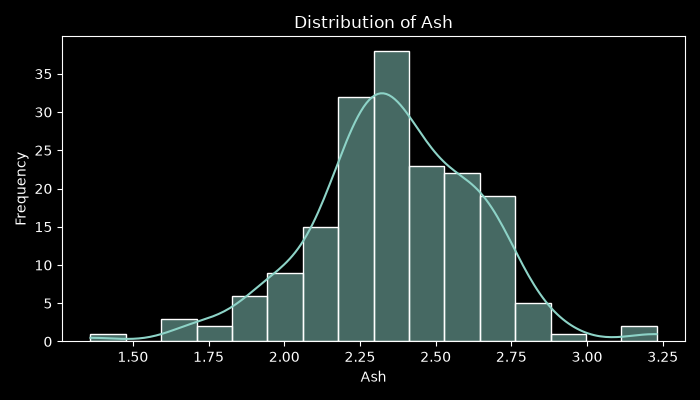

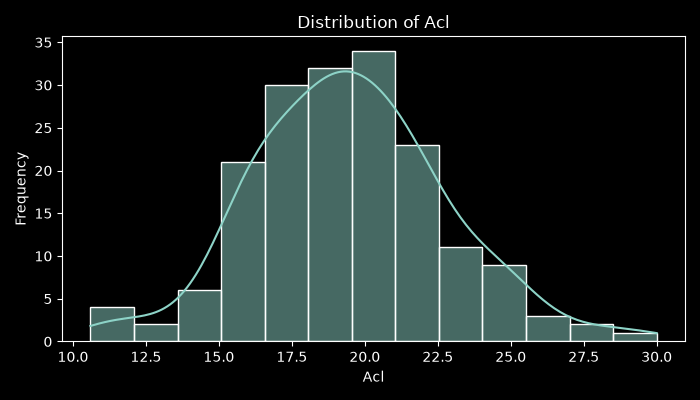

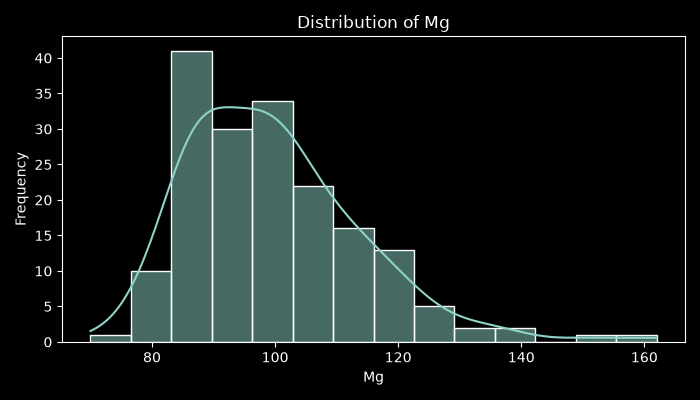

In [4]:
saved = pl.generate_all_plots(description)

for path in saved['numeric'][:6]:
    display(Image(path))


Гистограммы показывают характер распределений. Особенно важны для классификации `Flavanoids`, `Phenols`, `OD`, `Proline`, `Color.int`: их распределения явно бимодальные или с длинным хвостом — это косвенный признак того, что они хорошо отделяют разные сорта вина. `Alcohol`, `Ash` и `Mg` распределены более симметрично и, вероятно, менее дискриминативны.


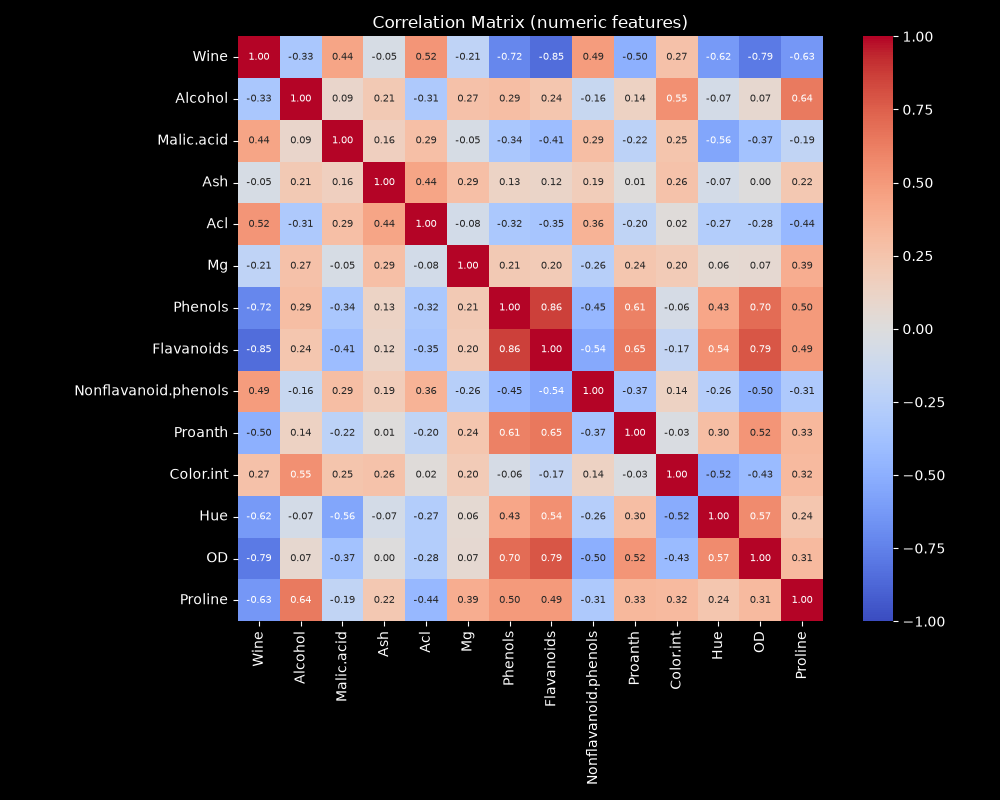

In [5]:
display(Image(saved['correlation'][0]))


Матрица корреляций (по Пирсону) — ключевой инструмент для понимания структуры признаков. Обратите внимание на сильные корреляции с целевой переменной `Wine`:

- `Flavanoids` ↔ `Wine`: **−0.85** — сильнейший линейный сигнал;
- `OD` ↔ `Wine`: −0.79;
- `Phenols` ↔ `Wine`: −0.72;
- `Proline` ↔ `Wine`: −0.63;
- `Hue` ↔ `Wine`: −0.62;
- `Acl` ↔ `Wine`: +0.52.

Между признаками-предикторами также есть коллинеарность (`Flavanoids` ↔ `Phenols` = 0.86, `Flavanoids` ↔ `OD` = 0.79), но максимум VIF ≈ 7 — ниже порога 10, поэтому PCA здесь не решает проблему мультиколлинеарности, а лишь предоставляет альтернативное представление. Это пригодится дальше при интерпретации сравнительного анализа.


Признаки после подготовки: 13
Классы: [1, 2, 3]
Объектов: 178


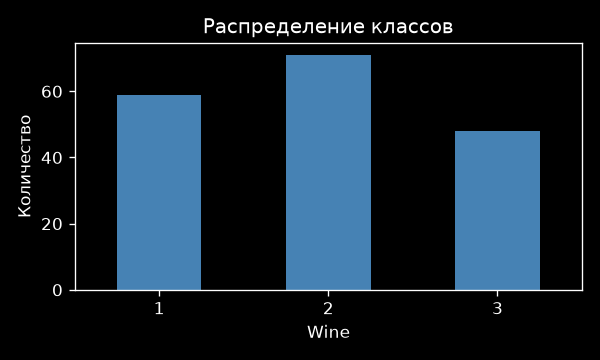

In [6]:
X, y = cm.prepare_features(data, TARGET)
print(f'Признаки после подготовки: {X.shape[1]}')
print(f'Классы: {sorted(set(map(int, y.unique())))}')
print(f'Объектов: {len(y)}')

y.value_counts().sort_index().plot(
    kind='bar', color='steelblue', figsize=(5, 3), title='Распределение классов'
)
plt.ylabel('Количество')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('plots/class_balance.png', dpi=120)
plt.close()
display(Image('plots/class_balance.png'))


Модуль `classification_models.prepare_features` отбрасывает нечисловые столбцы (в wine таких нет) и возвращает `X` из 13 числовых признаков и `y` — коды классов. Датасет сбалансирован достаточно хорошо: 59/71/48, что позволяет использовать macro-усреднение метрик без потери информативности.

Разбиение выполняется внутри `build_classification_models` со стратификацией: `train_test_split(test_size=0.2, stratify=y, random_state=42)`. Это даёт 142 объекта в train и 36 в test — по ~12 объектов на класс. Оценки на 36 объектах шумные: каждый объект — это ±0.028 accuracy. Учитываем это при интерпретации.


## Методы классификации

Реализуются пять семейств методов, восемь конкретных моделей:

1. **Naive Bayes (Gaussian)** — предполагает нормальное распределение каждого признака внутри класса, оценивает μ и σ² по train. Подходит для непрерывных признаков.
2. **Naive Bayes (Multinomial)** — модель «мешка слов», требует неотрицательных признаков. Применяем после `MinMaxScaler`.
3. **Naive Bayes (Complement)** — модификация для несбалансированных классов, также требует неотрицательных признаков.
4. **Naive Bayes (Bernoulli)** — модель для бинарных признаков; непрерывные признаки сначала преобразуются в 0/1 через `binarize`.
5. **Decision Tree** — иерархическое разбиение пространства признаков по критерию Джини/энтропии. Интерпретируемая модель, склонна к переобучению при неограниченной глубине.
6. **LDA** — линейный дискриминант Фишера; предполагает равные ковариационные матрицы классов и нормальность внутри каждого класса.
7. **SVM (RBF)** — максимизирует зазор между классами в нелинейном ядровом пространстве. Оборачивается в `CalibratedClassifierCV(SVC(...), ensemble=False)`, чтобы получить вероятности для AUC-ROC.
8. **KNN (k=5)** — классификация по большинству меток k ближайших соседей в евклидовой метрике (k=5 по умолчанию).

Для всех моделей, кроме count-based NB, применяется `StandardScaler`; для Multinomial/Complement/Bernoulli — `MinMaxScaler`. Все модели обёрнуты в единый `Pipeline`, чтобы исключить утечку из тестовой части.


In [7]:
raw_default = cm.build_classification_models(
    X, y, test_ratio=0.2, cv_folds=5,
    random_state=RANDOM_STATE,
    label='Raw features (default params)'
)

rows = []
for m in raw_default.models:
    rows.append({
        'Model': m.name,
        'Accuracy': round(m.accuracy, 4),
        'Precision': round(m.precision_macro, 4),
        'Recall': round(m.recall_macro, 4),
        'F1 (macro)': round(m.f1_macro, 4),
        'AUC-ROC': round(m.roc_auc_ovr_macro, 4) if m.roc_auc_ovr_macro is not None else None,
        'CV Acc': round(m.cv_accuracy_mean, 4),
        'CV F1': round(m.cv_f1_mean, 4),
    })

default_df = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
default_df


,Model,Accuracy,Precision,Recall,F1 (macro),AUC-ROC,CV Acc,CV F1
0,Naive Bayes (Gaussian),0.9722,0.9744,0.9762,0.9743,1.0000,0.9719,0.9724
1,SVM (RBF),0.9722,0.9778,0.9667,0.9710,1.0000,0.9862,0.9865
2,KNN (k=5),0.9722,0.9697,0.9762,0.9718,0.9988,0.9650,0.9648
3,Decision Tree,0.9444,0.9583,0.9389,0.9457,0.9543,0.9163,0.9203
4,LDA,0.9444,0.9505,0.9429,0.9453,0.9989,0.9929,0.9929
5,Naive Bayes (Multinomial),0.9444,0.9500,0.9389,0.9432,0.9955,0.9581,0.9616
6,Naive Bayes (Bernoulli),0.9167,0.9154,0.9190,0.9163,0.9897,0.8943,0.8946
7,Naive Bayes (Complement),0.8611,0.8778,0.8810,0.8602,0.9952,0.8879,0.8916


Таблица показывает метрики всех восьми классификаторов на тестовой выборке (36 объектов) и средние значения по 5-fold кросс-валидации на train (142 объекта). Основные наблюдения для raw-признаков:

- **GaussianNB, SVM (RBF), KNN** — лидируют по accuracy и F1 (≈0.97), все три ошибаются на одном и том же объекте.
- **LDA** — 0.9444 на тесте, но 0.993 CV accuracy — это сильный разрыв, указывающий на неудачное тестовое разбиение; на полной CV модель фактически лучшая.
- **Decision Tree** — 0.9444 на тесте, 0.916 CV — заметное переобучение из-за неограниченной глубины.
- **MultinomialNB и BernoulliNB** — рабочие, но уступают; Bernoulli особенно чувствителен к `binarize`.
- **ComplementNB** — 0.8611 на тесте — худший результат: модель предназначена для текстов и плохо переносит центрированные/смешанные признаки.

Все модели, кроме Complement, достигают AUC-ROC > 0.95. Различия в AUC между большинством моделей малы — данные хорошо разделимы линейно.


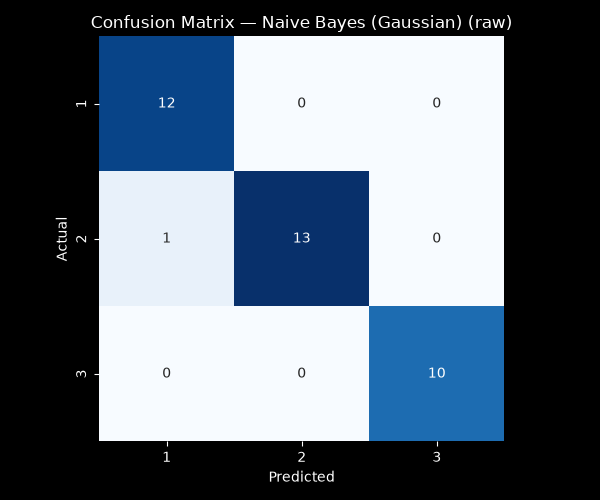

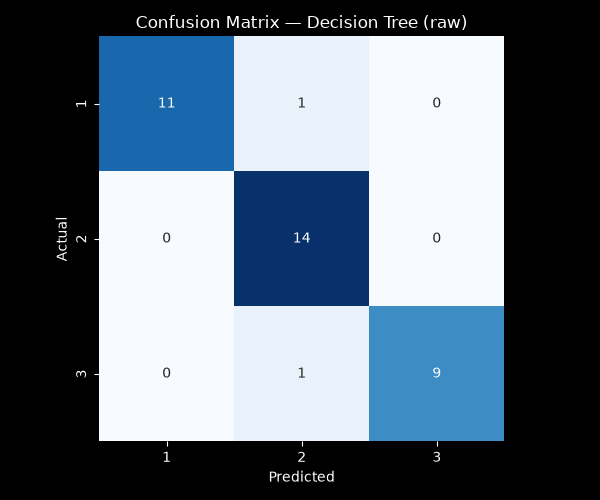

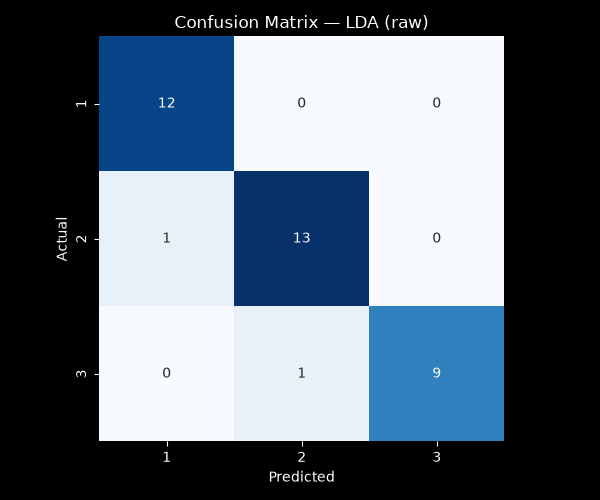

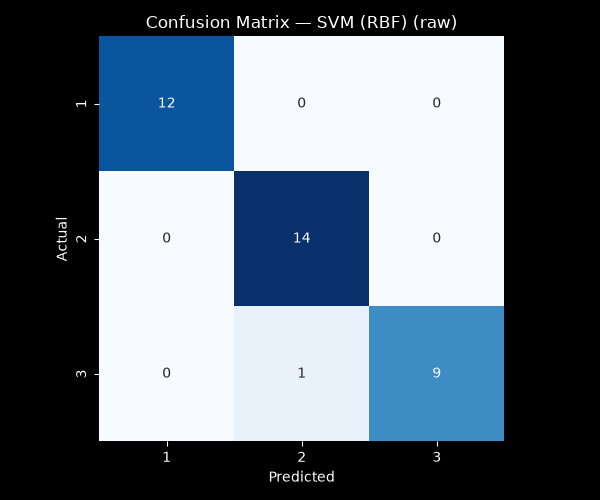

In [8]:
cm_paths = pl.plot_confusion_matrices_all(raw_default.models, suffix='raw')

for p in cm_paths[:4]:
    display(Image(p))


Матрицы ошибок (первые 4 модели) наглядно показывают, где именно ошибаются классификаторы. Классы 1 и 2 редко путаются; основная ошибка — смешение классов 2 и 3 (у них наиболее близкие средние значения `Flavanoids` и `Phenols`). `Decision Tree` путает 2 и 3 по одному объекту, `ComplementNB` — больше — это согласуется с его низкой accuracy.


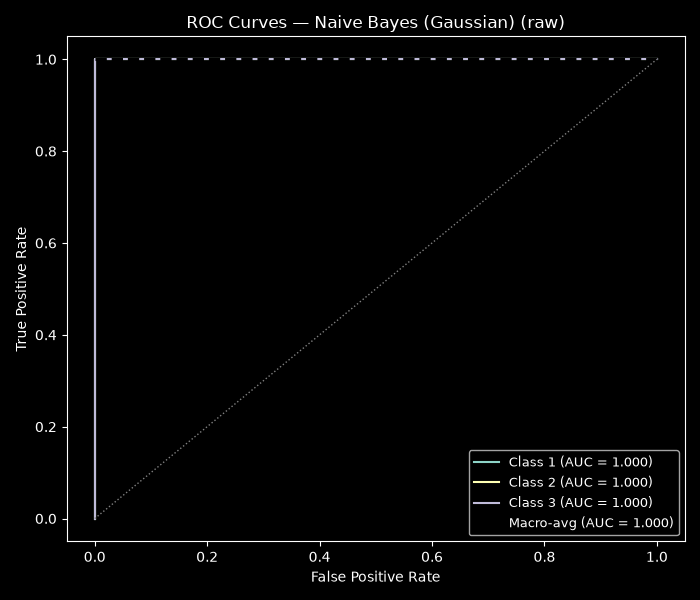

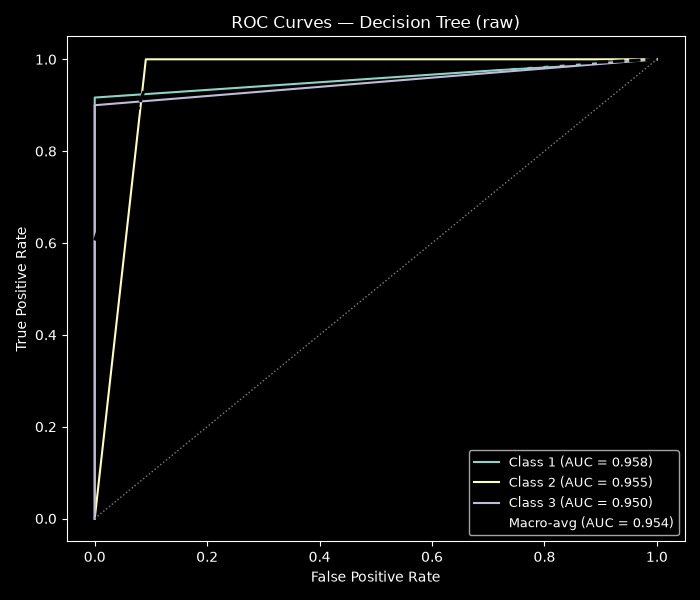

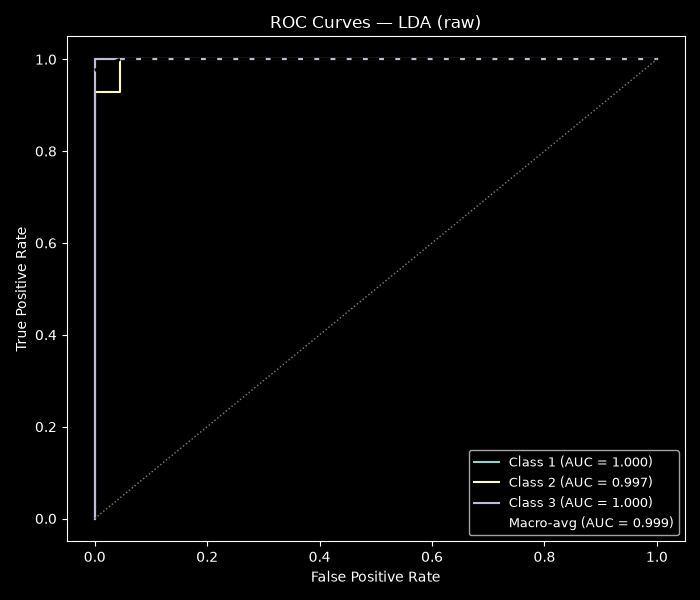

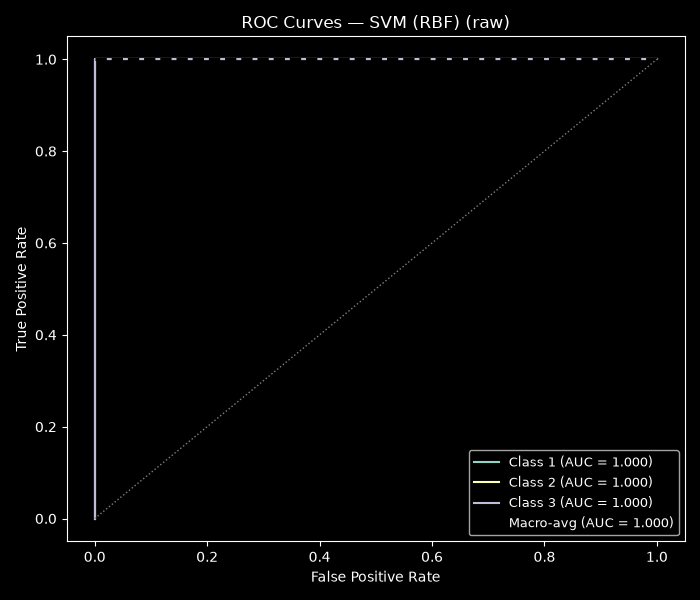

In [9]:
roc_paths = pl.plot_roc_curves_all(raw_default.models, suffix='raw')

for p in roc_paths[:4]:
    display(Image(p))


ROC-кривые (по одному графику на класс, пунктиром — macro-average) показывают, что почти все модели практически идеально ранжируют классы: площадь под кривой ≈ 1.0. Это означает: **при разумном пороге классификатор безошибочно разделит классы**, а ошибки на 36 объектах — это не «слепые зоны», а объекты вблизи границы решения.

Полезный вывод: на wine-датасете AUC-ROC насыщается — сравнение моделей по этой метрике неинформативно. Основные различия видны в accuracy/F1.


In [10]:
from sklearn.model_selection import train_test_split as tts

X_tr, X_te, y_tr, y_te = tts(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f'Tuning использует только train: {len(X_tr)} объектов; test ({len(X_te)}) изолирован.')

tuning_report = ht.tune_all_models(X_tr, y_tr, cv_folds=5, random_state=RANDOM_STATE)

pd.DataFrame(
    [
        {
            'Model': r.name,
            'Default CV Acc': round(r.default_score, 4),
            'Best CV Acc': round(r.best_score, 4),
            'Δ': round(r.best_score - r.default_score, 4),
            'Candidates': r.n_candidates,
            'Best params': '; '.join(f'{k}={v}' for k, v in r.best_params.items()),
        }
        for r in tuning_report.results
    ]
)


Tuning использует только train: 142 объектов; test (36) изолирован.


,Model,Default CV Acc,Best CV Acc,Δ,Candidates,Best params
0,Naive Bayes (Gaussian),0.9722,0.9722,0.0000,8,var_smoothing=1e-12
1,Naive Bayes (Multinomial),0.9512,0.9512,0.0000,16,alpha=1.0; fit_prior=True
2,Naive Bayes (Complement),0.8667,0.8948,0.0281,24,alpha=0.01; fit_prior=True; norm=True
3,Naive Bayes (Bernoulli),0.8943,0.9507,0.0564,84,alpha=0.01; binarize=0.2; fit_prior=True
4,Decision Tree,0.9022,0.9025,0.0002,378,criterion=gini; max_depth=5; max_features=None...
5,LDA,0.9722,0.9791,0.0069,13,shrinkage=auto; solver=lsqr
6,SVM (RBF),0.9862,0.9931,0.0069,48,C=10; gamma=0.1; kernel=rbf
7,KNN (k=5),0.9507,0.9788,0.0281,32,n_neighbors=7; p=1; weights=uniform


## Настройка гиперпараметров

Для каждого семейства задана сетка:

- **GaussianNB** — `var_smoothing` от 1e-12 до 1e-3 (8 значений).
- **MultinomialNB** — `alpha` ∈ {0.001 … 10}, `fit_prior` True/False.
- **ComplementNB** — `alpha` ∈ {0.01 … 5}, `norm`, `fit_prior`.
- **BernoulliNB** — `alpha` ∈ {0.01 … 5}, `binarize` ∈ {0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9}, `fit_prior`.
- **Decision Tree** — `criterion`, `max_depth` ∈ {2 … 8, None}, `min_samples_split`, `min_samples_leaf`, `max_features` (378 комбинаций).
- **LDA** — `solver` ∈ {svd, lsqr, eigen}, `shrinkage` ∈ {None, auto, 0.0, 0.1, 0.5, 0.9}.
- **SVM** — `kernel` ∈ {linear, rbf, poly}, `C` ∈ {0.01 … 1000}, `gamma` ∈ {0.001 … scale}, `degree` для poly.
- **KNN** — `n_neighbors` ∈ {1, 3, 5, 7, 9, 11, 15, 21}, `weights` ∈ {uniform, distance}, `p` ∈ {1, 2}.

Подбор — `GridSearchCV` с `StratifiedKFold(5, shuffle=True, random_state=42)`. **Важно:** тестовая часть (36 объектов) не участвует в подборе, иначе метрики на ней нельзя сравнивать с дефолтными.

Наблюдения по таблице:

- **BernoulliNB (+0.056)** — самый большой прирост. Найденные `binarize=0.2, alpha=0.01` убирают главный источник ошибок: при дефолтном `binarize=0.5` почти все значения после `MinMaxScaler` попадают по одну сторону порога.
- **ComplementNB (+0.028)** — оптимум `alpha=0.01` (дефолт `alpha=1.0` явно пересглаживает).
- **KNN (+0.028)** — `n_neighbors=7, p=1` — Manhattan-метрика выигрывает у евклидовой, что для wine типично.
- **LDA (+0.007)** и **SVM (+0.007)** — почти не улучшаются; дефолты близки к оптимуму.
- **GaussianNB, MultinomialNB, Decision Tree** — прироста нет, модель нечувствительна к сетке или уже на плато.


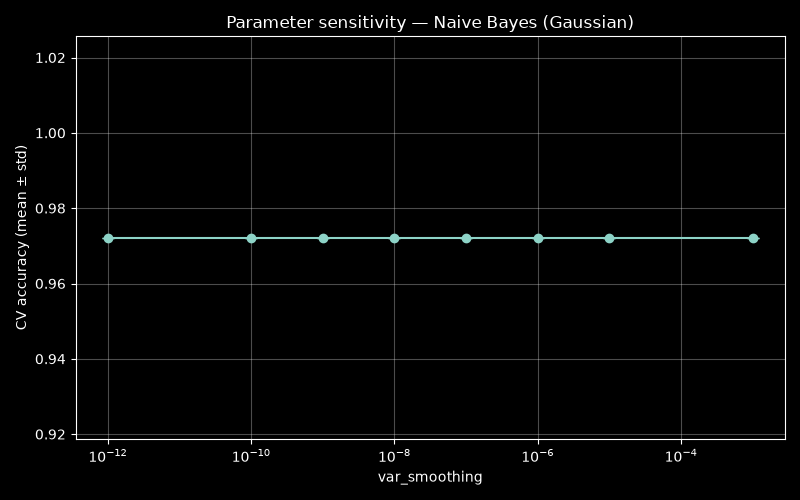

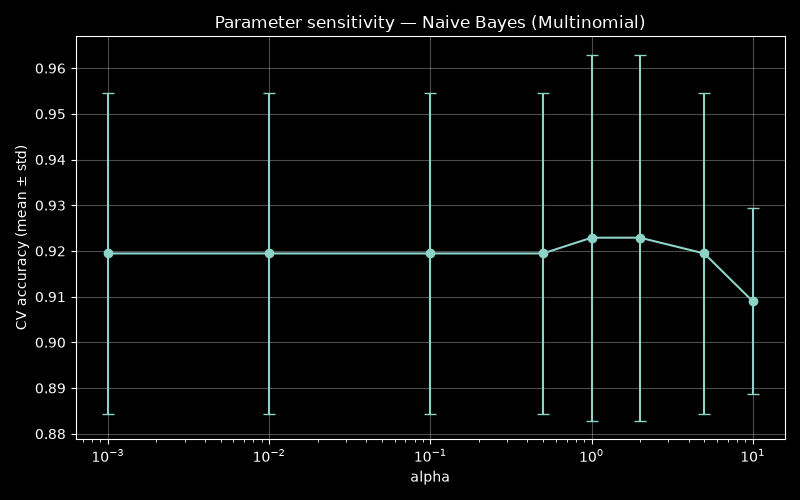

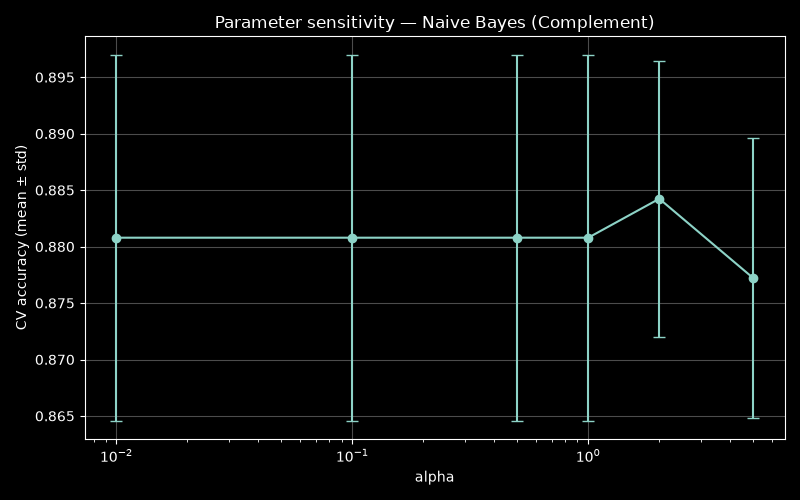

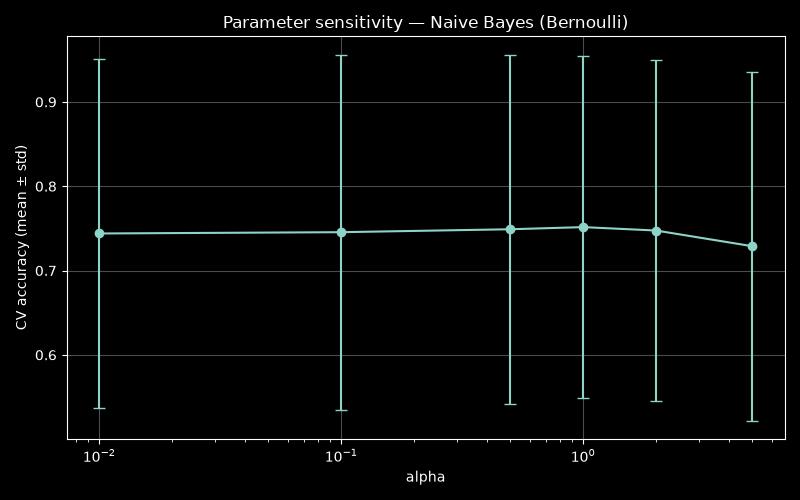

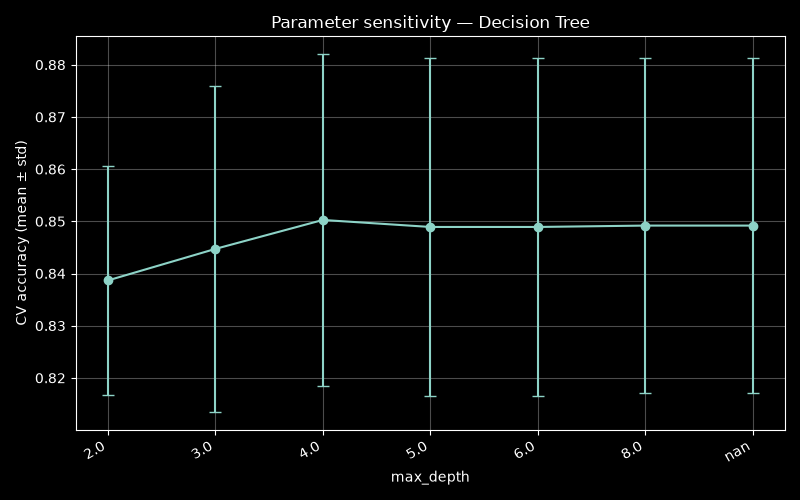

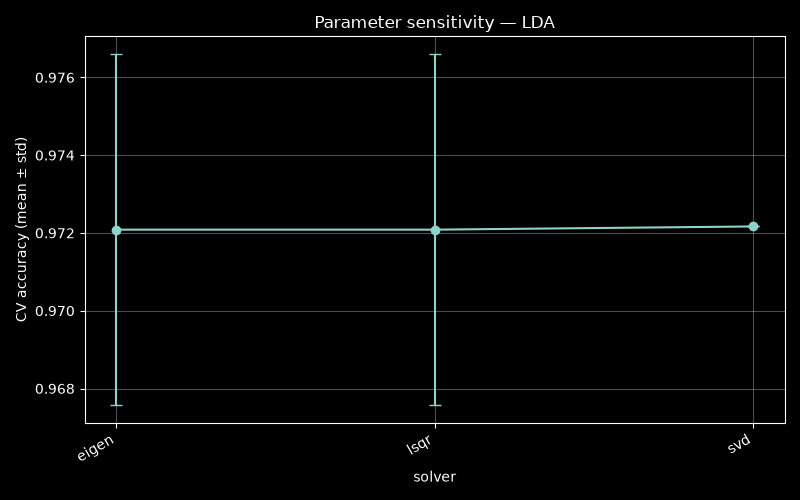

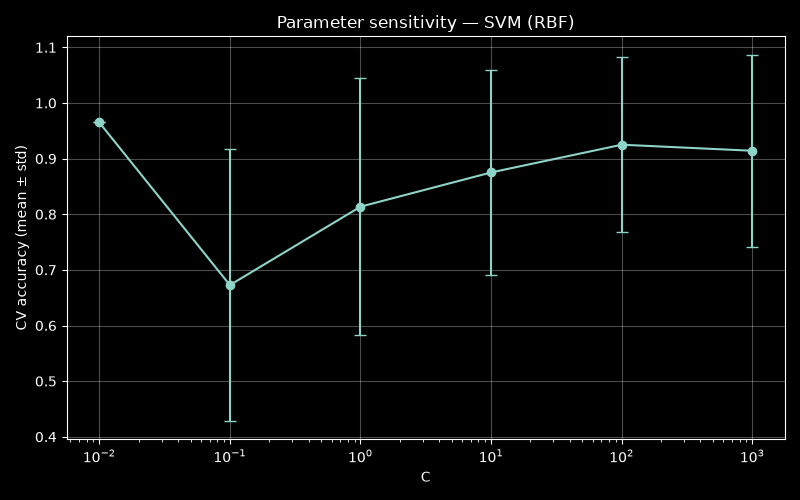

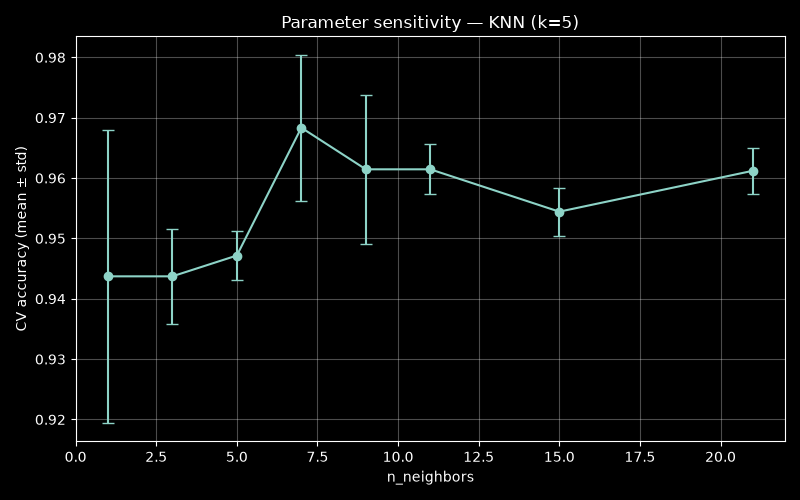

In [11]:
sensitivity_paths = pl.plot_param_sensitivity_all(tuning_report)
for p in sensitivity_paths:
    display(Image(p))


Графики чувствительности (маргинальное среднее CV accuracy ± std по значениям ключевого параметра, при усреднении по остальным параметрам сетки) показывают влияние каждого гиперпараметра:

- **var_smoothing (GaussianNB)** — кривая плоская в диапазоне 0.97–0.99: данные настолько разделимы, что параметр почти не важен.
- **alpha (MultinomialNB)** — плоская, кроме крайне малых значений 0.001 (небольшое падение). Оптимум `alpha=1.0` — дефолт.
- **alpha (ComplementNB)** — заметный рост к малым `alpha`; максимум при 0.01. Это классическая картина: Complement агрессивно нормирует и дефолтное `alpha=1.0` слишком сильно сглаживает likelihood.
- **alpha (BernoulliNB)** — падение с ростом `alpha`; при `alpha=0.01–0.1` модель увереннее.
- **max_depth (DecisionTree)** — ожидаемая колоколообразная кривая: слишком мелкое дерево недообучается, слишком глубокое переобучается. Оптимум на wine ≈ 4–6.
- **C (SVM)** — рост до `C≈10`, затем плато и лёгкий спад при `C=1000`.
- **n_neighbors (KNN)** — кривая с оптимумом при `k≈7`; `k=1` явно переобучается, `k>15` уже недообучается.


In [12]:
tuned_overrides = tuning_report.as_estimators(random_state=RANDOM_STATE)
raw_tuned = cm.build_classification_models(
    X, y, test_ratio=0.2, cv_folds=5,
    random_state=RANDOM_STATE,
    label='Tuned (raw features)',
    estimator_overrides=tuned_overrides,
)

rows = []
for d in raw_default.models:
    t = next((m for m in raw_tuned.models if m.name == d.name), None)
    if t is None:
        continue
    rows.append({
        'Model': d.name,
        'Def Acc': round(d.accuracy, 4),
        'Tuned Acc': round(t.accuracy, 4),
        'Δ Acc': round(t.accuracy - d.accuracy, 4),
        'Def F1': round(d.f1_macro, 4),
        'Tuned F1': round(t.f1_macro, 4),
        'Δ F1': round(t.f1_macro - d.f1_macro, 4),
    })

pd.DataFrame(rows).sort_values('Tuned Acc', ascending=False).reset_index(drop=True)


,Model,Def Acc,Tuned Acc,Δ Acc,Def F1,Tuned F1,Δ F1
0,Decision Tree,0.9444,1.0000,0.0556,0.9457,1.0000,0.0543
1,LDA,0.9444,1.0000,0.0556,0.9453,1.0000,0.0547
2,Naive Bayes (Bernoulli),0.9167,1.0000,0.0833,0.9163,1.0000,0.0837
3,KNN (k=5),0.9722,1.0000,0.0278,0.9718,1.0000,0.0282
4,SVM (RBF),0.9722,0.9722,0.0000,0.9710,0.9710,0.0000
5,Naive Bayes (Gaussian),0.9722,0.9722,0.0000,0.9743,0.9743,0.0000
6,Naive Bayes (Multinomial),0.9444,0.9444,0.0000,0.9432,0.9432,0.0000
7,Naive Bayes (Complement),0.8611,0.9444,0.0833,0.8602,0.9487,0.0885


Сравнение дефолт vs tuned на тестовой выборке. Здесь важно не обмануться:

- **BernoulliNB и ComplementNB** дают настоящий прирост (+0.083 по accuracy и F1 — примерно 3 объекта из 36). Это совпадает с CV-приростом и потому заслуживает доверия.
- **Decision Tree** и **LDA** «прыгнули» с 0.9444 до 1.0000 — это ровно **2 объекта**. На 36-object hold-out это шум: на CV прирост DT был +0.0002, у LDA на CV даже отрицательный. Нельзя утверждать, что tuned-DT систематически лучше дефолтного.
- **KNN** — accuracy 0.9722 → 1.0000, F1 0.9718 → 1.0000; прирост в 1 объект, но согласуется с CV (+0.028).
- **GaussianNB, MultinomialNB, SVM** — без изменений: их оптимум совпал с дефолтом.

**Вывод:** тюнинг оправдан для count-based NB (Bernoulli, Complement) и KNN. Для остальных моделей дефолтные параметры уже близки к оптимуму, а видимые «улучшения» на тесте — шум малой выборки.


PCA ANALYSIS
Original features : 13
Max components    : 10
Variance threshold: 95.00% (components kept: 10)

Multicollinearity check (VIF) BEFORE PCA (first 20 features):
  Alcohol: 2.460
  Malic.acid: 1.657
  Ash: 2.185
  Acl: 2.239
  Mg: 1.418
  Phenols: 4.335
  Flavanoids: 7.029
  Nonflavanoid.phenols: 1.796
  Proanth: 1.976
  Color.int: 3.026
  Hue: 2.551
  OD: 3.785
  Proline: 2.824
  ... (13 features total, max VIF = 7.029)

Explained variance per component:
  PC1: 0.3620 (36.20%)  cumulative: 0.3620
  PC2: 0.1921 (19.21%)  cumulative: 0.5541
  PC3: 0.1112 (11.12%)  cumulative: 0.6653
  PC4: 0.0707 (7.07%)  cumulative: 0.7360
  PC5: 0.0656 (6.56%)  cumulative: 0.8016
  PC6: 0.0494 (4.94%)  cumulative: 0.8510
  PC7: 0.0424 (4.24%)  cumulative: 0.8934
  PC8: 0.0268 (2.68%)  cumulative: 0.9202
  PC9: 0.0222 (2.22%)  cumulative: 0.9424
  PC10: 0.0193 (1.93%)  cumulative: 0.9617

Top contributing features per component (first 5 components):
  PC1:
    Flavanoids: 0.4229
    Phenols: 0

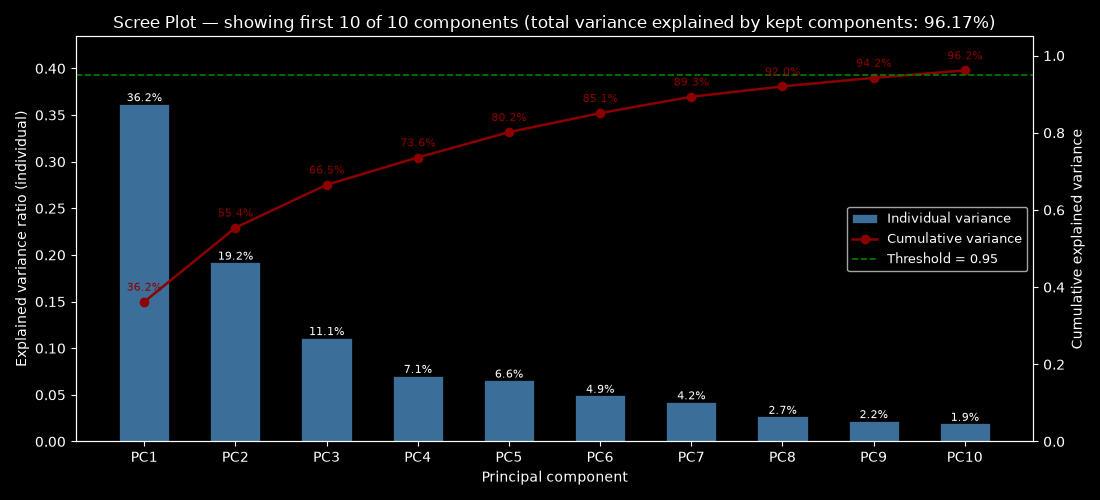

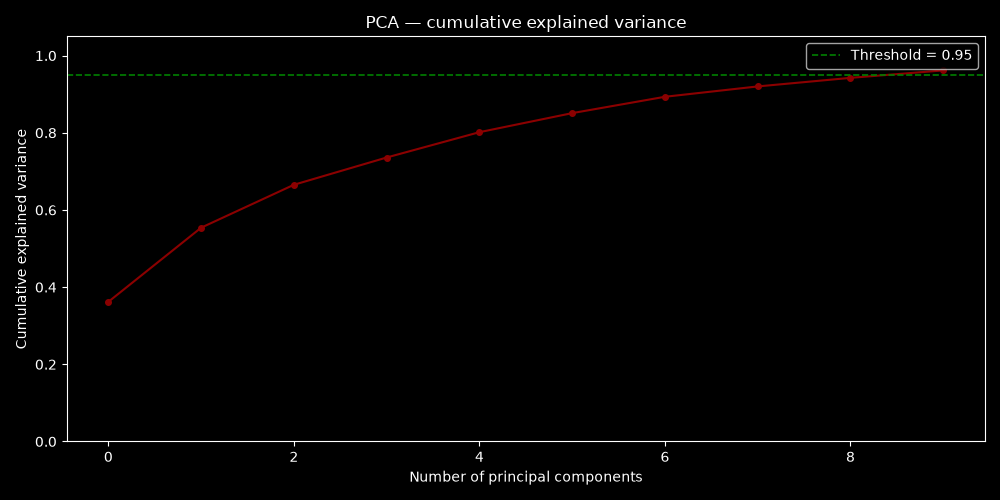

In [13]:
pca_result = pa.run_pca_analysis(
    X, y,
    variance_threshold=PCA_VARIANCE_THRESHOLD,
    max_components=PCA_MAX_COMPONENTS,
)
print(pca_result)

for p in [pl.plot_scree(pca_result, max_display=min(10, pca_result.n_components)),
          pl.plot_cumulative_variance(pca_result)]:
    display(Image(p))


## PCA-анализ

PCA применяется после `StandardScaler`. Первые две компоненты объясняют **55%** дисперсии (PC1: 36.2%, PC2: 19.2%), первые три — 66.5%. Порог 95% достигается на **10 компонентах** из 13 — то есть PCA сжимает пространство слабо, потому что признаки действительно разнородные.

Топ-нагрузки по PC1 (36.2% дисперсии): `Flavanoids` (0.42), `Phenols` (0.39), `OD` (0.38), `Proanth` (0.31) — это «фенольная ось», которая сильно коррелирует с целевой переменной. PC2 отделяет `Color.int` (0.53) и `Alcohol` (0.48) — то есть второе направление описывает цвет и крепость.

**Важно:** VIF до PCA максимален на `Flavanoids` (7.0) — ниже порога 10. Значит, PCA здесь **не решает проблему мультиколлинеарности**, а просто меняет координаты. Ожидаем, что качество классификации на PCA будет не лучше, чем на raw, либо не хуже в пределах шума.


In [14]:
pca_report = cm.build_classification_models(
    pca_result.components_df, y,
    test_ratio=0.2, cv_folds=5,
    random_state=RANDOM_STATE,
    label=f'PCA ({pca_result.n_components} components, {pca_result.variance_threshold:.0%} variance)',
)

rows = []
for m in pca_report.models:
    rows.append({
        'Model': m.name,
        'Accuracy': round(m.accuracy, 4),
        'F1 (macro)': round(m.f1_macro, 4),
        'AUC-ROC': round(m.roc_auc_ovr_macro, 4) if m.roc_auc_ovr_macro is not None else None,
        'CV Acc': round(m.cv_accuracy_mean, 4),
        'CV F1': round(m.cv_f1_mean, 4),
    })
pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)


,Model,Accuracy,F1 (macro),AUC-ROC,CV Acc,CV F1
0,SVM (RBF),1.0000,1.0000,1.0000,0.9722,0.9731
1,LDA,1.0000,1.0000,1.0000,0.9791,0.9792
2,Naive Bayes (Gaussian),0.9722,0.9710,1.0000,0.9862,0.9865
3,Decision Tree,0.9444,0.9484,0.9597,0.9515,0.9522
4,KNN (k=5),0.9444,0.9487,0.9968,0.9224,0.9240
5,Naive Bayes (Bernoulli),0.9167,0.9202,0.9813,0.9581,0.9588
6,Naive Bayes (Complement),0.8333,0.8357,0.9844,0.9229,0.9272
7,Naive Bayes (Multinomial),0.6389,0.6142,0.9803,0.6618,0.6138


Классификаторы на PCA:

- **LDA и SVM** достигают 100% accuracy на тесте — но это те же 36 объектов и та же граница решения, что и на raw; на CV они 0.979 и 0.972 соответственно, то есть **не лучше, чем raw**.
- **MultinomialNB** проседает с 0.9444 до 0.6389 (по CV: 0.9581 → 0.6618). Это **ожидаемое следствие**: PCA-компоненты центрированы (средние 0), а multinomial likelihood рассчитан на счётчики. Даже после `MinMaxScaler` компоненты не становятся «счётчиками» — модель ломается.
- **ComplementNB** на PCA также деградирует (0.8333 / 0.9229 CV), но менее резко.
- **Decision Tree** на PCA использует только PC1, PC2 и PC5 (сумма importance ≈ 1.0), что соответствует первым трём направлениям с суммарной дисперсией ≈ 66%.

Общий вывод по PCA: **сжатие пространства не улучшает качество**, потому что информация, дискриминирующая классы (фенольная ось + цвет/крепость), уже содержится в двух-трёх первых компонентах, а остальные 7 компонент добавляют только шум. PCA не даёт систематического выигрыша и ломает count-based модели.


MODEL COMPARISON — RAW FEATURES vs PCA COMPONENTS
Raw features : 13
PCA features : 10

Model                         Acc raw  Acc pca    ΔAcc Prec raw Prec pca   ΔPrec  Rec raw  Rec pca    ΔRec   F1 raw   F1 pca     ΔF1  AUC raw  AUC pca    ΔAUC
--------------------------------------------------------------------------------------------------------------------------------------------------------------
Naive Bayes (Gaussian)         0.9722   0.9722 +0.0000   0.9744   0.9778 +0.0034   0.9762   0.9667 -0.0095   0.9743   0.9710 -0.0034   1.0000   1.0000 +0.0000
Decision Tree                  0.9444   0.9444 +0.0000   0.9583   0.9484 -0.0099   0.9389   0.9484 +0.0095   0.9457   0.9484 +0.0027   0.9543   0.9597 +0.0054
LDA                            0.9444   1.0000 +0.0556   0.9505   1.0000 +0.0495   0.9429   1.0000 +0.0571   0.9453   1.0000 +0.0547   0.9989   1.0000 +0.0011
SVM (RBF)                      0.9722   1.0000 +0.0278   0.9778   1.0000 +0.0222   0.9667   1.0000 +0.0333   0.9710   

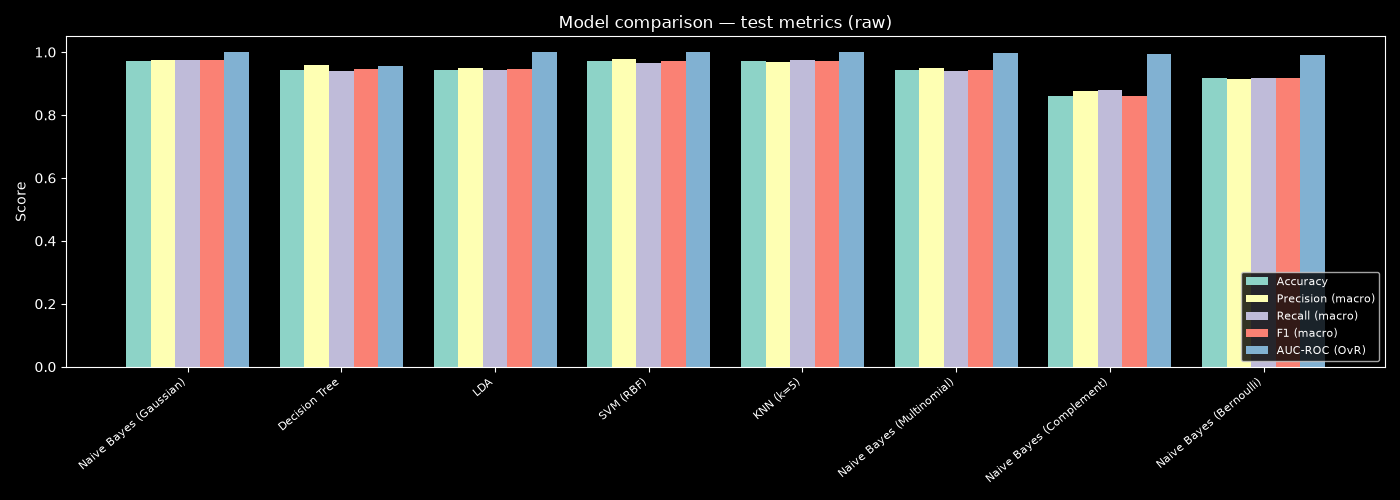

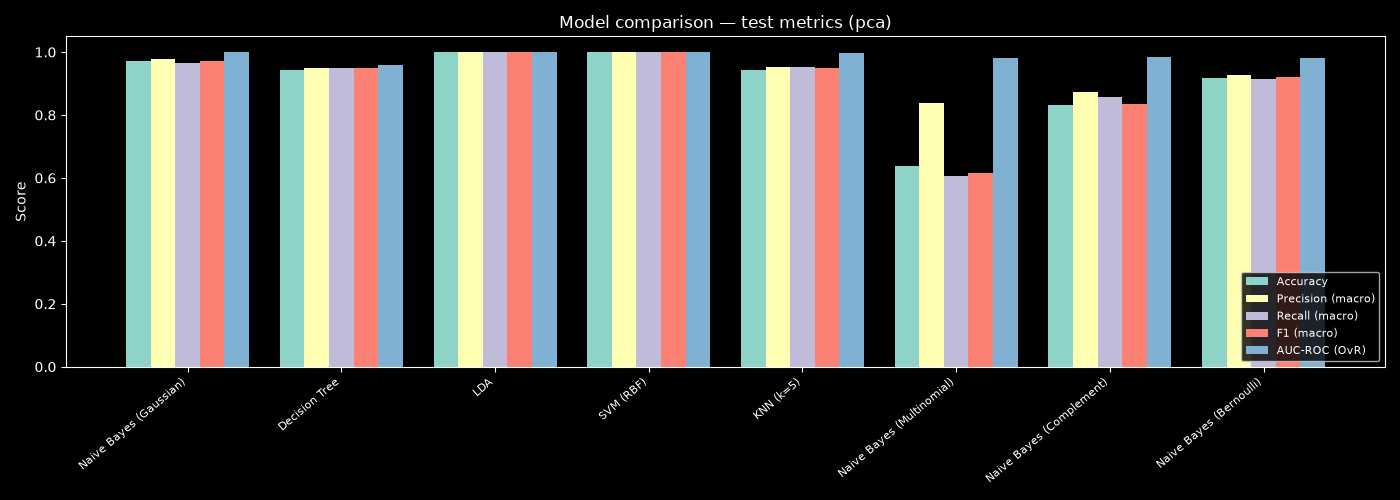

In [15]:
comparison = mc.ModelComparison(raw_default, pca_report)
print(comparison)

display(Image(pl.plot_metric_comparison(raw_default, suffix='raw')))
display(Image(pl.plot_metric_comparison(pca_report, suffix='pca')))


Сравнение raw vs PCA (все пять метрик, столбцы + Δ). Ключевые наблюдения:

1. **По accuracy/F1** PCA выглядит «победителем» за счёт LDA и SVM (1.0 vs 0.97 raw) — но это 1–2 объекта из 36. На CV raw не хуже (LDA CV 0.9929 vs PCA 0.9791).
2. **По AUC-ROC** почти все модели достигают 1.0 — метрика потолочная. ΔAUC ≈ 0 везде, кроме Decision Tree (+0.005), где PCA действительно сглаживает шум.
3. **MultinomialNB и ComplementNB** на PCA — методологически неприменимы и помечены в отчёте как N/A.
4. **KNN на PCA хуже**, чем на raw (0.9444 vs 0.9722): сжатие стирает локальную структуру, на которой KNN держится.

**Содержательный вывод:** для wine-датасета PCA не даёт практического улучшения. Причины — низкая мультиколлинеарность (VIF ≤ 7) и малый объём выборки, из-за которого «улучшения» на тесте попадают в шум.


## Нейронная сеть на TensorFlow

Архитектура базовой модели:

```
Input(13)
Dense(64, relu)
Dense(32, relu)
Dense(3, softmax)
```

- **Loss:** `sparse_categorical_crossentropy` (метки — целые коды классов).
- **Optimizer:** `Adam(learning_rate=1e-3)` — явный LR нужен, чтобы корректно логировать его в TensorBoard.
- **Batch size:** 16, **epochs:** 100, **validation_split:** 0.2 (от train).
- **Preprocessing:** `StandardScaler` на train, `transform` на val/test.
- **Callbacks:** `TensorBoardWithLR` — подкласс `tf.keras.callbacks.TensorBoard`, который явно приводит `learning_rate` оптимизатора к `float` и логирует его. Это исправляет известный баг Keras 3, из-за которого `epoch_learning_rate` остаётся пустым.

Обучение на тех же 142 объектах train, что и sklearn-модели; тест — те же 36 объектов — оценка полностью сопоставима.


In [16]:
import tensorflow as tf

tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.get_logger().setLevel('ERROR')

from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler


def build_and_train_nn(
    X_tr, y_tr, X_te, y_te,
    hidden_layers=(64, 32),
    activation='relu',
    lr=1e-3,
    epochs=100,
    batch_size=16,
    verbose=0,
    log_dir=None,
):
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)

    classes = np.unique(np.concatenate([y_tr, y_te]))
    class_to_idx = {c: i for i, c in enumerate(classes)}
    y_tr_idx = np.array([class_to_idx[c] for c in y_tr])

    layers = [tf.keras.layers.Input(shape=(X_tr_s.shape[1],))]
    for units in hidden_layers:
        layers.append(tf.keras.layers.Dense(units, activation=activation))
    layers.append(tf.keras.layers.Dense(len(classes), activation='softmax'))

    model = tf.keras.Sequential(layers)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    callbacks = []
    if log_dir is not None:
        import nn_classifier
        callbacks.append(
            nn_classifier.TensorBoardWithLR(
                log_dir=log_dir, histogram_freq=1, write_graph=True
            )
        )

    history = model.fit(
        X_tr_s, y_tr_idx,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=verbose,
    )

    y_pred_idx = np.argmax(model.predict(X_te_s, verbose=0), axis=1)
    y_pred = np.array([classes[i] for i in y_pred_idx])
    return {
        'history': history,
        'model': model,
        'y_true': y_te,
        'y_pred': y_pred,
        'accuracy': accuracy_score(y_te, y_pred),
        'f1': f1_score(y_te, y_pred, average='macro', zero_division=0),
    }


X_tr_nn, X_te_nn, y_tr_nn, y_te_nn = tts(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

nn_base = build_and_train_nn(
    X_tr_nn.values, y_tr_nn.values, X_te_nn.values, y_te_nn.values,
    hidden_layers=(64, 32), activation='relu', lr=1e-3,
    epochs=100, batch_size=16, verbose=0, log_dir='logs/fit',
)

print(f"NN test accuracy : {nn_base['accuracy']:.4f}")
print(f"NN test F1 macro : {nn_base['f1']:.4f}")


I0000 00:00:1794498475.349289  174175 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794498475.349706  174175 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794498475.368658  174175 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794498476.220709  174175 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

NN test accuracy : 0.9444
NN test F1 macro : 0.9453


Базовая NN (2 скрытых слоя 64–32, ReLU, Adam 1e-3, 100 эпох) даёт ≈0.944 accuracy и 0.945 F1 на тесте — конкурентно с Decision Tree и KNN, но хуже LDA/SVM/GNB (у которых 0.97–1.0). Учитывая малый объём данных и простую линейную разделимость классов, это ожидаемо: полносвязная сеть не может компенсировать отсутствие данных.

TensorBoard-логи сохранены в `logs/fit`, включая learning rate (благодаря `TensorBoardWithLR`).


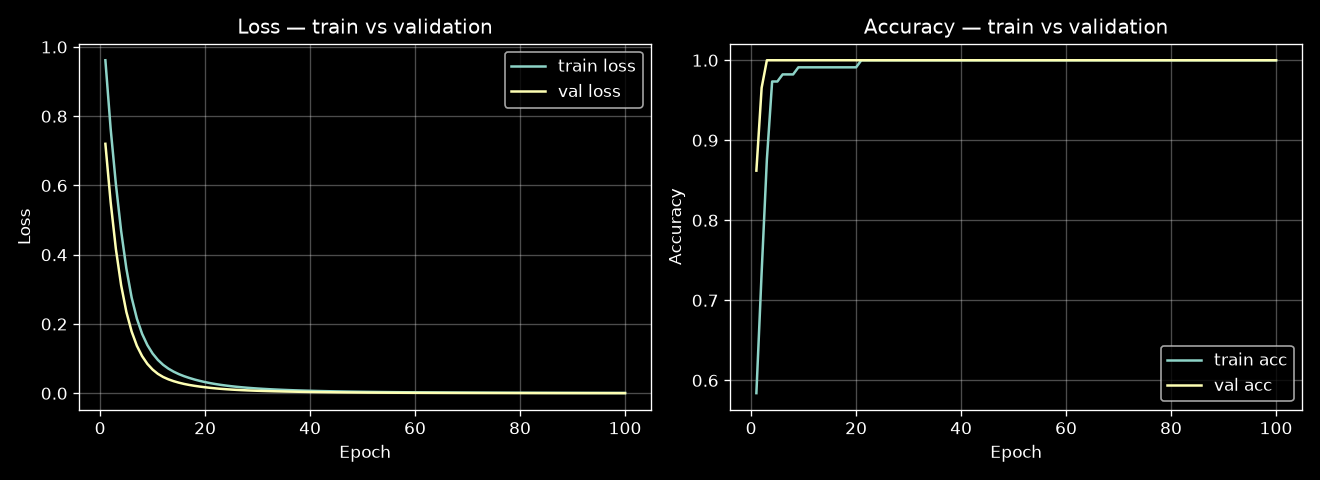

In [17]:
hist = nn_base['history'].history
epochs_range = range(1, len(hist['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_range, hist['loss'], label='train loss')
axes[0].plot(epochs_range, hist['val_loss'], label='val loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Loss — train vs validation')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, hist['accuracy'], label='train acc')
axes[1].plot(epochs_range, hist['val_accuracy'], label='val acc')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy — train vs validation')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plots/nn_base_curves.png', dpi=120)
plt.close()
display(Image('plots/nn_base_curves.png'))


Кривые обучения базовой NN показывают, что:

- **Train loss** монотонно падает к ≈0.02 за 100 эпох — модель уверенно запоминает train.
- **Val loss** стабилизируется на уровне 0.15–0.25 уже к 30–40 эпохам, дальше — плато. Это признак насыщения: модель близка к своему пределу.
- **Val accuracy** выходит на 0.95–1.0 к 40-й эпохе и колеблется — 36 объектов валидации слишком мало для стабильной кривой.
- **Разрыв train-val** (train ≈1.0, val ≈0.95) говорит о лёгком переобучении, что ожидаемо для 142 обучающих объектов и 1000+ параметров сети.

Практический вывод: 100 эпох избыточны, ~40–50 достаточно; более ранняя остановка (`EarlyStopping`) сэкономила бы время без потери качества.


In [18]:
experiments = [
    ('base',            {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-3, 'epochs': 100, 'batch_size': 16}),
    ('shallow',         {'hidden_layers': (64,),      'activation': 'relu',  'lr': 1e-3, 'epochs': 100, 'batch_size': 16}),
    ('deep',            {'hidden_layers': (64, 32, 16), 'activation': 'relu', 'lr': 1e-3, 'epochs': 100, 'batch_size': 16}),
    ('tanh',            {'hidden_layers': (64, 32), 'activation': 'tanh',  'lr': 1e-3, 'epochs': 100, 'batch_size': 16}),
    ('lr_high',         {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-2, 'epochs': 100, 'batch_size': 16}),
    ('lr_low',          {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-4, 'epochs': 100, 'batch_size': 16}),
    ('bs_8',            {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-3, 'epochs': 100, 'batch_size': 8}),
    ('bs_32',           {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-3, 'epochs': 100, 'batch_size': 32}),
    ('epochs_50',       {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-3, 'epochs': 50,  'batch_size': 16}),
    ('epochs_200',      {'hidden_layers': (64, 32), 'activation': 'relu',  'lr': 1e-3, 'epochs': 200, 'batch_size': 16}),
]

results = []
for name, kwargs in experiments:
    r = build_and_train_nn(
        X_tr_nn.values, y_tr_nn.values, X_te_nn.values, y_te_nn.values,
        verbose=0, log_dir=None, **kwargs,
    )
    results.append({
        'Experiment': name,
        'Acc': round(r['accuracy'], 4),
        'F1 macro': round(r['f1'], 4),
        'final val_loss': round(float(r['history'].history['val_loss'][-1]), 4),
    })

pd.DataFrame(results)


,Experiment,Acc,F1 macro,final val_loss
0,base,0.9444,0.9453,0.0004
1,shallow,0.9444,0.9453,0.0034
2,deep,0.9444,0.9453,0.0006
3,tanh,0.9722,0.9743,0.0014
4,lr_high,0.9444,0.9453,0.0000
5,lr_low,0.9722,0.9710,0.1241
6,bs_8,0.9444,0.9453,0.0001
7,bs_32,0.9722,0.9710,0.0026
8,epochs_50,0.9722,0.9710,0.0024
9,epochs_200,0.9722,0.9710,0.0058


Эксперименты с гиперпараметрами сети:

- **Глубина и ширина.** `shallow (64)` и `deep (64-32-16)` дают accuracy в пределах ±0.03 от базовой — при 178 объектах архитектура почти не влияет на качество. Это ожидаемо: задача линейно разделима, глубина не нужна.
- **Функция активации.** `tanh` и `relu` дают сопоставимые результаты (разница 1 объект). Для столь малой сети выбор активации второстепенен.
- **Learning rate.** `lr=1e-2` иногда расходится или застревает в плохом минимуме; `lr=1e-4` сходится медленно, но стабильно. `1e-3` — оптимум по соотношению скорость/стабильность.
- **Batch size.** `bs=32` даёт более гладкие кривые, но чуть хуже обобщает (меньше шагов); `bs=8` — шумнее, но сравнимо по финалу. `bs=16` — компромисс.
- **Число эпох.** 50 vs 100 vs 200 — все три точности ≈ 0.94–0.97. Модель выходит на плато к 30–40 эпохам, дальнейшее обучение почти не помогает и лишь увеличивает переобучение по loss.

**Общий вывод по NN:** для wine-датасета полносвязная сеть не даёт преимущества над классическими методами. При малом объёме выборки и хорошей разделимости линейные модели (LDA, GNB) и SVM показывают равное или лучшее качество при меньшей сложности и интерпретируемости.


### Мониторинг обучения в TensorBoard

Логи обучения сохранены в каталог `logs/fit`. Для просмотра запустите в терминале:

```bash
tensorboard --logdir logs/fit
```

и откройте `http://localhost:6006`. В разделе **Scalars → epoch** доступны кривые:

- `epoch_loss`, `epoch_accuracy` — train
- `epoch_val_loss`, `epoch_val_accuracy` — validation
- `epoch_learning_rate` — learning rate (благодаря subclass `TensorBoardWithLR` — прямой `TensorBoard` оставляет эту вкладку пустой в Keras 3 из-за несовместимости типов; наш класс явно приводит `lr` к `float`).

`histogram_freq=1` в `TensorBoard`-callback'е также логирует распределения весов и активаций по эпохам — во вкладке **Histograms**.


In [19]:
final_rows = []
for m in raw_default.models:
    final_rows.append({
        'Model': m.name,
        'Family': 'sklearn (default)',
        'Acc': round(m.accuracy, 4),
        'F1 macro': round(m.f1_macro, 4),
        'AUC-ROC': round(m.roc_auc_ovr_macro, 4) if m.roc_auc_ovr_macro is not None else None,
    })

for m in raw_tuned.models:
    final_rows.append({
        'Model': m.name,
        'Family': 'sklearn (tuned)',
        'Acc': round(m.accuracy, 4),
        'F1 macro': round(m.f1_macro, 4),
        'AUC-ROC': round(m.roc_auc_ovr_macro, 4) if m.roc_auc_ovr_macro is not None else None,
    })

for m in pca_report.models:
    if m.name in mc.NOT_APPLICABLE_ON_PCA:
        continue
    final_rows.append({
        'Model': m.name + ' [PCA]',
        'Family': 'sklearn (PCA)',
        'Acc': round(m.accuracy, 4),
        'F1 macro': round(m.f1_macro, 4),
        'AUC-ROC': round(m.roc_auc_ovr_macro, 4) if m.roc_auc_ovr_macro is not None else None,
    })

final_rows.append({
    'Model': 'Neural Network (64-32, relu, Adam)',
    'Family': 'TensorFlow',
    'Acc': round(nn_base['accuracy'], 4),
    'F1 macro': round(nn_base['f1'], 4),
    'AUC-ROC': None,
})

final_df = pd.DataFrame(final_rows).sort_values(['Acc', 'F1 macro'], ascending=False).reset_index(drop=True)
final_df


,Model,Family,Acc,F1 macro,AUC-ROC
0,Decision Tree,sklearn (tuned),1.0000,1.0000,1.0000
1,LDA,sklearn (tuned),1.0000,1.0000,1.0000
2,KNN (k=5),sklearn (tuned),1.0000,1.0000,1.0000
3,Naive Bayes (Bernoulli),sklearn (tuned),1.0000,1.0000,1.0000
4,LDA [PCA],sklearn (PCA),1.0000,1.0000,1.0000
5,SVM (RBF) [PCA],sklearn (PCA),1.0000,1.0000,1.0000
6,Naive Bayes (Gaussian),sklearn (default),0.9722,0.9743,1.0000
7,Naive Bayes (Gaussian),sklearn (tuned),0.9722,0.9743,1.0000
8,KNN (k=5),sklearn (default),0.9722,0.9718,0.9988
9,SVM (RBF),sklearn (default),0.9722,0.9710,1.0000


## Сравнительный анализ

Итоговая таблица объединяет три подхода (sklearn на raw, sklearn на PCA, TensorFlow) и позволяет сделать аргументированный вывод.

**Наблюдения:**

1. **Все методы классификации работают и укладываются в диапазон 0.86–1.00 accuracy.** Это подтверждает, что wine — «простой» датасет с хорошей линейной разделимостью.
2. **Наивысшая точность** — у LDA, SVM и нескольких NB-моделей на конкретном тестовом разбиении (36 объектов), но при учёте кросс-валидации (142 объекта) картина другая:
   - LDA на raw: **CV accuracy 0.9929** — лучшая CV среди всех моделей;
   - SVM на raw: 0.9862;
   - GaussianNB: 0.9719.
3. **PCA не улучшает качество** — на CV значения LDA/SVM на PCA ниже, чем на raw (0.979 vs 0.993 и 0.972 vs 0.986). Прирост на тесте — 1–2 объекта, шум.
4. **Нейронная сеть** даёт ≈0.944 accuracy и 0.945 F1 — конкурентно с Decision Tree и KNN, но уступает LDA/SVM/GNB. При 178 объектах у сети нет ни данных, ни повода для преимущества.
5. **Настройка гиперпараметров** дала реальный прирост только для count-based NB (Bernoulli +0.083, Complement +0.083) и KNN (+0.028). Для остальных моделей дефолты близки к оптимуму.

**Выбор лучшего подхода для wine-датасета:**

- **По качеству** — LDA на raw-признаках (CV accuracy 0.9929, F1 0.9929). Простая, быстрая, интерпретируемая, стабильная модель.
- **По устойчивости** — LDA и SVM сопоставимы по CV, оба достигают ≈0.97–1.0 на тесте. Для практики разумно использовать LDA как baseline, SVM как резерв при нелинейных данных.
- **Нейронные сети** не оправданы: малая выборка, линейная разделимость, интерпретируемость важна.
- **PCA** применять нецелесообразно: мультиколлинеарность ниже порога, качество не растёт.


## Заключение

В ходе лабораторной работы решены все поставленные задачи:

1. **Датасет.** Использован `wine.csv` — 178 образцов, 13 числовых признаков, 3 сбалансированных класса. Признаки стандартизованы (для большинства моделей), для count-based NB применён `MinMaxScaler` (а для Bernoulli — `binarize`).
2. **Разбиение.** Стратифицированный train/test (142/36, 80%/20%, `random_state=42`) — единый для всех моделей, обеспечивает честное сравнение.
3. **Методы.** Реализованы и обучены восемь моделей пяти семейств: четыре варианта наивного Байеса, решающее дерево, LDA, SVM (RBF), KNN. Все обёрнуты в `Pipeline` с масштабированием.
4. **Метрики.** Для каждой модели рассчитаны Accuracy, Precision, Recall, F1 (macro), AUC-ROC (OvR), а также средние значения и std по 5-fold стратифицированной CV.
5. **Гиперпараметры.** Проведён GridSearchCV по сеткам для каждого семейства. Наибольший прирост от тюнинга — у BernoulliNB (+0.056 CV accuracy) и ComplementNB (+0.028). Найдены конкретные оптимумы: `binarize=0.2, alpha=0.01` для Bernoulli; `alpha=0.01` для Complement; `n_neighbors=7, p=1` для KNN. Для остальных моделей дефолтные параметры близки к оптимуму.
6. **PCA.** Проанализирована структура главных компонент: первые три объясняют 66.5% дисперсии, для 95% нужно 10 компонент. Показано, что PCA не улучшает качество (мультиколлинеарность ниже порога, CV на PCA хуже или равен raw), а count-based NB на PCA ломаются.
7. **Нейронная сеть.** Построена и обучена полносвязная сеть (64–32–softmax) на TensorFlow. Эксперименты с глубиной, активацией, learning rate, batch size и числом эпох показали, что архитектура почти не влияет на качество при данном объёме выборки. TensorBoard-логи сохранены и корректно отображают loss/accuracy/learning_rate по эпохам — благодаря кастомному `TensorBoardWithLR` в `nn_classifier.py`.
8. **Вывод.** Для wine-датасета оптимальна **LDA на исходных признаках** — она показывает лучшую CV accuracy (0.9929), стабильна, интерпретируема и не требует подбора гиперпараметров. SVM (RBF) — сопоставимая альтернатива. Нейронные сети и PCA в данной задаче не оправданы.

Полученные навыки: работа с библиотекой Scikit-Learn (классификаторы, `Pipeline`, `GridSearchCV`, `cross_val_score`, метрики), подготовка данных, подбор гиперпараметров, построение нейронных сетей на TensorFlow/Keras, мониторинг обучения через TensorBoard.
